# 서울시 따릉이(공공자전거) 이용량 × 날씨 데이터 분석

- 명세서: `데이터분석_및_시각화PJT_명세서.pdf` (데이터 분석 및 시각화, 4회차)
- 담당 범위: **F401 ~ F404** (본 노트북 작성자)
- 2차 담당(F405~F406): 신현준
- 상세 계획/협업 방식: [`PLAN.md`](../PLAN.md), [`docs/collaboration_guide.md`](../docs/collaboration_guide.md)
- 데이터 출처·수집 기록: [`docs/data_collection_log.md`](../docs/data_collection_log.md)


## F401. 분석 문제 및 데이터 선정

### 분석 주제
**기상 조건(기온·강수·바람·습도)이 서울시 공공자전거(따릉이)의 일별 이용량에 미치는 영향**

### 분석 질문
1. **(주질문)** 일별 평균기온·강수량·풍속·습도는 일별 대여건수와 어떤 상관관계를 보이는가?
2. 비(강수)가 있었던 날과 없었던 날의 대여건수 차이는 유의미한가?
3. 월별(계절별)로 이용량 패턴과 날씨 영향력이 달라지는가?
4. 2025년과 2026년 동일 기간(1~6월)을 비교했을 때 이용량 추세에 변화가 있는가?

질문 2~4는 F404(EDA/시각화) 단계에서 2차 담당자가 본격적으로 탐색하며, 본 노트북(F401~F403)에서는
이 질문에 **답할 수 있는 데이터 형태**를 만드는 것까지를 범위로 한다.

### 사용 데이터
| 데이터셋 | 설명 | 기간 |
|---|---|---|
| 서울특별시 공공자전거 일별 대여건수 | 서울시 전체 따릉이 일별 대여건수 합계 (3개 CSV: 25.1-6 / 25.7-12 / 26.1-6) | 2025-01-01 ~ 2026-06-30 |
| 기상청 ASOS 108(서울) 일자료 | 서울 종관기상관측소(지점번호 108)의 일별 기상 관측값 | 2025-01-01 ~ 2026-10-14 |

### 분석 단위
**일(day) 단위, 서울시 전체** — 따릉이 데이터가 대여소별이 아닌 서울시 합산 일별 집계로 제공되므로,
분석 단위를 자연스럽게 "일자(date)"로 맞추고 ASOS 서울 관측소(108) 일자료와 날짜 기준으로 1:1 결합한다.

### 주요 변수 (선정)
- **종속변수**: `rentals` (일별 대여건수)
- **독립변수(후보)**: `avgTa`(평균기온), `minTa`(최저기온), `maxTa`(최고기온), `sumRn`(일강수량),
  `avgWs`(평균풍속), `avgRhm`(평균습도)
- 그 외 ASOS 컬럼(지면 상태, 일조/일사, 적설 등)은 결측이 많거나 분석 질문과 관련성이 낮아 F403에서 제외 여부를 판단한다.

### 선정 근거
- 두 데이터 모두 **공공데이터(서울 열린데이터광장 / 기상자료개방포털)** 로 출처가 명확하고 **일 단위로 기간이 거의 일치**해 결합이 쉽다.
- 따릉이는 서울의 대표적인 생활 교통수단이라 **날씨 민감도**를 확인하는 것이 실용적인 인사이트(운영·재배치 전략 등)로 이어질 수 있다.
- 두 데이터 모두 결측·형식 이슈가 있어(아래 F401 데이터 확인에서 검증) **정제 연습(F403)에도 적합**하다.


In [1]:
import pandas as pd

pd.set_option('display.max_columns', 20)


### 데이터 불러오기 및 기초 확인 (F401 근거 검증용)

In [2]:
bike_files = [
    "../data/raw/서울특별시 공공자전거 일별 대여건수_25.1-6.csv",
    "../data/raw/서울특별시 공공자전거 일별 대여건수_25.7-12.csv",
    "../data/raw/서울특별시 공공자전거 일별 대여건수_26.1-6.csv",
]

# 원본 CSV는 EUC-KR(cp949) 인코딩으로 저장되어 있어 UTF-8로 읽으면 헤더가 깨진다.
bike = pd.concat(
    [pd.read_csv(f, encoding="cp949") for f in bike_files],
    ignore_index=True,
)
bike.columns = ["date", "rentals"]
bike["date"] = pd.to_datetime(bike["date"])

print(bike.shape)
bike.head()


(546, 2)


,date,rentals
0,2025-01-01,48645
1,2025-01-02,77718
2,2025-01-03,77053
3,2025-01-04,56597
4,2025-01-05,19712


In [3]:
print("기간:", bike["date"].min().date(), "~", bike["date"].max().date())
print("중복 날짜 수:", bike["date"].duplicated().sum())

full_range = pd.date_range(bike["date"].min(), bike["date"].max(), freq="D")
missing_dates = full_range.difference(bike["date"])
print("빠진 날짜 수:", len(missing_dates))

bike["rentals"].describe()


기간: 2025-01-01 ~ 2026-06-30
중복 날짜 수: 0
빠진 날짜 수: 0


count       546.000000
mean     101377.441392
std       42067.699373
min        9975.000000
25%       66669.000000
50%      106466.500000
75%      138007.750000
max      176011.000000
Name: rentals, dtype: float64

In [4]:
asos = pd.read_csv("../data/raw/asos_108_daily_20250101_20261014.csv", encoding="utf-8")
asos["tm"] = pd.to_datetime(asos["tm"])

print(asos.shape)
print("기간:", asos["tm"].min().date(), "~", asos["tm"].max().date())
print("관측 지점:", asos[["stnId", "stnNm"]].drop_duplicates().to_dict("records"))

key_cols = ["tm", "avgTa", "minTa", "maxTa", "sumRn", "avgWs", "avgRhm"]
asos[key_cols].head()


(652, 62)
기간: 2025-01-01 ~ 2026-10-14
관측 지점: [{'stnId': 108, 'stnNm': '서울'}]


,tm,avgTa,minTa,maxTa,sumRn,avgWs,avgRhm
0,2025-01-01,2.6,-2.5,8.9,NaN,2.2,64.3
1,2025-01-02,0.5,-2.9,6.0,NaN,2.1,48.8
2,2025-01-03,-1.1,-5.1,3.2,0.0,2.2,52.0
3,2025-01-04,-0.1,-5.4,5.7,NaN,1.7,49.6
4,2025-01-05,1.2,-0.7,2.5,6.7,2.5,85.0


In [5]:
asos[key_cols].isna().sum()


tm          0
avgTa       0
minTa       0
maxTa       0
sumRn     386
avgWs       0
avgRhm      0
dtype: int64

### F401 데이터 확인 결과 해석

- 따릉이 데이터는 3개 파일을 합쳐 **546행**, 2025-01-01~2026-06-30 **연속 일자**이며 중복·누락 날짜가 없다.
  일별 대여건수는 평균 약 101,377건, 최소 9,975건~최대 176,011건으로 계절/날씨에 따른 변동 폭이 크다는 점이
  관찰된다(해석: 겨울철 저조, 여름철 급증 가능성 — 자세한 패턴 분석은 F404에서 수행).
- ASOS 데이터는 **652행**으로 2026-10-14까지 포함되어 따릉이 기간(~2026-06-30)보다 길다 →
  병합 시 따릉이 기간 기준으로 inner join 하면 자동으로 범위가 맞춰진다(F403에서 처리).
- 핵심 기상 변수 중 `avgTa`/`minTa`/`maxTa`/`avgWs`/`avgRhm`은 결측이 없고, `sumRn`(일강수량)만
  386일 결측이다. 이는 센서 미관측이 아니라 **강수가 없었던 날 공란으로 기록되는 ASOS 관례**로 보이며,
  F403에서 0으로 대체할지 별도 "강수 여부" 플래그로 다룰지 근거와 함께 결정한다.
- 두 데이터 모두 날짜 기준 결합이 가능하고(F401에서 정한 분석 단위: 일/서울시 전체), 결측·인코딩 이슈가
  명확히 파악되어 F403(정제) 진행이 가능한 상태임을 확인했다.

**다음 단계**: F402(수집 기록은 `docs/data_collection_log.md`에 별도 정리 완료) → F403(인코딩 통일,
날짜 범위 정렬, 결측 처리, 병합 후 `data/processed/`에 저장).


## F402. 데이터 수집 및 출처 기록

상세 기록(출처 URL, 수집 방법, 수집 시점, 이용 조건 전문)은 [`docs/data_collection_log.md`](../docs/data_collection_log.md)에
표로 정리했다. 아래는 핵심 요약과, 두 원본 데이터를 **분석 가능한 형태(일관된 인코딩·컬럼명·날짜 타입)** 로
표준화해 `data/processed/`에 저장하는 과정이다.

| 데이터셋 | 출처 | 수집 방법 | 수집 시점 | 데이터 범위 | 이용 조건 |
|---|---|---|---|---|---|
| 따릉이 일별 대여건수 | 서울 열린데이터광장 — "서울시 공공자전거 따릉이 이용현황"(OA-14994), https://data.seoul.go.kr/dataList/OA-14994/F/1/datasetView.do | CSV 직접 다운로드 | 2026-10-15 | 2025-01-01~2026-06-30 | 공공누리 1유형: 출처표시 (상업적 이용 및 변경 가능) |
| ASOS 108(서울) 일자료 | 기상청_지상(종관,ASOS) 일자료 조회서비스 (공공데이터포털 ID 15059093), 실제 다운로드는 기상자료개방포털(data.kma.go.kr) | CSV 직접 다운로드 | 2026-10-15 | 2025-01-01~2026-10-14 | 공공저작물 출처표시(제1유형), 무료 |

두 데이터셋 모두 출처·수집방법·시점·이용조건을 공식 페이지에서 확인 완료했다(상세: `docs/data_collection_log.md`).


In [6]:
import os

os.makedirs("../data/processed", exist_ok=True)

# F401에서 이미 cp949/UTF-8로 올바르게 읽은 bike, asos를 재사용해
# "분석 가능한 형태(일관 인코딩·컬럼명)"로 표준화하여 저장한다.
# (값 자체의 정제·결측 처리는 F403에서 수행하며, 여기서는 형식만 표준화한다.)

bike_out_path = "../data/processed/bike_rentals_raw_utf8.csv"
asos_out_path = "../data/processed/asos_108_raw_utf8.csv"

bike.to_csv(bike_out_path, index=False, encoding="utf-8")
asos.to_csv(asos_out_path, index=False, encoding="utf-8")

print("저장 완료:", bike_out_path, bike.shape)
print("저장 완료:", asos_out_path, asos.shape)


저장 완료: ../data/processed/bike_rentals_raw_utf8.csv (546, 2)
저장 완료: ../data/processed/asos_108_raw_utf8.csv (652, 62)


### F402 결과 요약

- 두 원본 데이터 모두 공공데이터 포털에서 CSV로 직접 받은 자료이며, 출처·수집 방법·시점·범위·이용 조건을
  `docs/data_collection_log.md`에 표로 기록했다(이 노트북에는 요약만 포함).
- 원본의 인코딩 차이(따릉이 CSV는 cp949, ASOS는 UTF-8)를 통일해 `data/processed/`에 UTF-8로 저장함으로써
  "분석 가능한 형태"로 확보했다(F402 요구사항 충족). 값 자체의 정제(결측 처리 등)는 F403에서 이어서 수행한다.


## F403. 정제 및 데이터 품질 점검

F402에서 표준화한 `bike`, `asos`를 대상으로 **결측·중복·자료형·값의 범위**를 점검하고,
F401에서 정한 주요 변수만 선별해 분석용 스키마로 병합한다.


### 1) 자료형 및 중복 점검

In [7]:
print("bike dtypes"); print(bike.dtypes)
print()
print("asos[key_cols] dtypes"); print(asos[key_cols].dtypes)
print()
print("bike 날짜 중복:", bike["date"].duplicated().sum())
print("asos 날짜 중복:", asos["tm"].duplicated().sum())


bike dtypes
date       datetime64[us]
rentals             int64
dtype: object

asos[key_cols] dtypes
tm        datetime64[us]
avgTa            float64
minTa            float64
maxTa            float64
sumRn            float64
avgWs            float64
avgRhm           float64
dtype: object

bike 날짜 중복: 0
asos 날짜 중복: 0


### 2) 값의 범위 점검 (이상치/불가능값 여부)

In [8]:
checks = {
    "rentals >= 0": (bike["rentals"] >= 0).all(),
    "minTa <= avgTa <= maxTa": (asos["minTa"] <= asos["avgTa"]).all() and (asos["avgTa"] <= asos["maxTa"]).all(),
    "avgWs >= 0": (asos["avgWs"] >= 0).all(),
    "avgRhm in [0,100]": asos["avgRhm"].between(0, 100).all(),
    "sumRn >= 0 (결측 제외)": (asos["sumRn"].dropna() >= 0).all(),
}
for name, ok in checks.items():
    print(f"{name}: {'OK' if ok else 'FAIL'}")


rentals >= 0: OK
minTa <= avgTa <= maxTa: OK
avgWs >= 0: OK
avgRhm in [0,100]: OK
sumRn >= 0 (결측 제외): OK


모든 범위 점검을 통과했다 — 값 자체의 이상치(물리적으로 불가능한 값)는 없는 것으로 확인된다.

### 3) 결측치 처리
- `sumRn`(일강수량)의 결측 386건은 F402에서 확인한 대로 **ASOS 관례상 강수가 없었던 날의 공란**으로 판단해 `0`으로 채운다.
  동시에 "비가 왔는지 여부"를 별도 플래그(`is_rain`)로 남겨, 결측-대체가 "비 안 옴"과 "실제 0.0mm 관측"을 구분하지
  못하게 되는 정보 손실을 완화한다.
- 그 외 사용 변수(`avgTa`, `minTa`, `maxTa`, `avgWs`, `avgRhm`)는 결측이 없어 별도 처리가 필요 없다.


In [9]:
asos_clean = asos[["tm", "avgTa", "minTa", "maxTa", "sumRn", "avgWs", "avgRhm"]].copy()
asos_clean["is_rain"] = asos_clean["sumRn"].notna() & (asos_clean["sumRn"] > 0)
asos_clean["sumRn"] = asos_clean["sumRn"].fillna(0.0)

asos_clean.isna().sum()


tm         0
avgTa      0
minTa      0
maxTa      0
sumRn      0
avgWs      0
avgRhm     0
is_rain    0
dtype: int64

### 4) 병합 (분석 단위: 일자 × 서울시 전체)

F401에서 정한 분석 단위에 맞춰 `bike`(날짜 기준)와 `asos_clean`(날짜 기준)을 **inner join** 한다.
ASOS가 더 넓은 기간(~2026-10-14)을 포함하므로, inner join 결과는 자연스럽게 따릉이 데이터 범위
(~2026-06-30)로 맞춰질 것으로 예상하고, 실제로 행 손실이 없는지 확인한다.


In [10]:
merged = bike.merge(asos_clean, left_on="date", right_on="tm", how="inner").drop(columns=["tm"])
merged = merged.rename(columns={
    "avgTa": "avg_temp",
    "minTa": "min_temp",
    "maxTa": "max_temp",
    "sumRn": "precip_mm",
    "avgWs": "avg_wind",
    "avgRhm": "avg_humidity",
})

print("merged shape:", merged.shape)
print("bike 행 수 대비 손실:", len(bike) - len(merged))
merged.head()


merged shape: (546, 9)
bike 행 수 대비 손실: 0


,date,rentals,avg_temp,min_temp,max_temp,precip_mm,avg_wind,avg_humidity,is_rain
0,2025-01-01,48645,2.6,-2.5,8.9,0.0,2.2,64.3,False
1,2025-01-02,77718,0.5,-2.9,6.0,0.0,2.1,48.8,False
2,2025-01-03,77053,-1.1,-5.1,3.2,0.0,2.2,52.0,False
3,2025-01-04,56597,-0.1,-5.4,5.7,0.0,1.7,49.6,False
4,2025-01-05,19712,1.2,-0.7,2.5,6.7,2.5,85.0,True


In [11]:
merged.describe()


,date,rentals,avg_temp,min_temp,max_temp,precip_mm,avg_wind,avg_humidity
count,546,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000
mean,2025-09-30 12:00:00,101377.441392,13.116300,8.904945,17.977656,3.436447,2.333883,62.448168
min,2025-01-01 00:00:00,9975.000000,-9.700000,-13.200000,-6.100000,0.000000,1.100000,29.400000
25%,2025-05-17 06:00:00,66669.000000,3.825000,0.300000,8.600000,0.000000,1.900000,51.825000
50%,2025-09-30 12:00:00,106466.500000,13.700000,8.750000,19.150000,0.000000,2.200000,62.350000
75%,2026-02-13 18:00:00,138007.750000,22.375000,17.900000,27.100000,0.300000,2.700000,72.875000
max,2026-06-30 00:00:00,176011.000000,32.800000,29.300000,38.000000,126.700000,6.300000,98.100000
std,NaN,42067.699373,10.824224,11.014584,10.932977,11.752881,0.619504,14.332079


In [12]:
merged_out_path = "../data/processed/merged_daily.csv"
merged.to_csv(merged_out_path, index=False, encoding="utf-8")
print("저장 완료:", merged_out_path, merged.shape)


저장 완료: ../data/processed/merged_daily.csv (546, 9)


### F403 결과 요약

- 자료형·중복·값 범위 점검 결과 **이상치나 불가능한 값은 발견되지 않았다.**
- 유일한 품질 이슈는 `sumRn`(일강수량) 결측 386건이었고, **"무강수 → 결측 표기"라는 ASOS 관례**를 근거로
  0으로 대체하되 `is_rain` 플래그로 원래 정보를 보존했다. (이 가정이 틀릴 가능성은 F405 한계에서 다룬다.)
- `bike`(546행, 2025-01-01~2026-06-30)와 `asos_clean`을 날짜 기준 inner join 한 결과 **행 손실 없이 546행**이
  유지되어, 분석 단위(일자×서울시 전체)로 두 데이터가 빠짐없이 결합됨을 확인했다.
- 최종 산출물은 `data/processed/merged_daily.csv`(컬럼: `date, rentals, avg_temp, min_temp, max_temp,
  precip_mm, is_rain, avg_wind, avg_humidity`)이며, F404(EDA/시각화)부터는 이 파일을 바로 사용하면 된다.


## F404. 탐색적 데이터 분석 및 시각화

F403에서 만든 `merged`(= `data/processed/merged_daily.csv`)를 사용해, F401에서 정한 분석 질문
① 날씨-대여량 상관관계, ② 강수 여부에 따른 차이, ③ 계절/월별 변화, ④ 2025 vs 2026 비교 순으로
분포 → 집단 차이 → 시간 변화 → 변수 간 관계를 살펴본다.


In [13]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

df = merged.copy()
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["yearmonth"] = df["date"].dt.to_period("M").astype(str)

df.head()


,date,rentals,avg_temp,min_temp,max_temp,precip_mm,avg_wind,avg_humidity,is_rain,year,month,yearmonth
0,2025-01-01,48645,2.6,-2.5,8.9,0.0,2.2,64.3,False,2025,1,2025-01
1,2025-01-02,77718,0.5,-2.9,6.0,0.0,2.1,48.8,False,2025,1,2025-01
2,2025-01-03,77053,-1.1,-5.1,3.2,0.0,2.2,52.0,False,2025,1,2025-01
3,2025-01-04,56597,-0.1,-5.4,5.7,0.0,1.7,49.6,False,2025,1,2025-01
4,2025-01-05,19712,1.2,-0.7,2.5,6.7,2.5,85.0,True,2025,1,2025-01


### 1) 기초 통계·분포 — 일별 대여건수

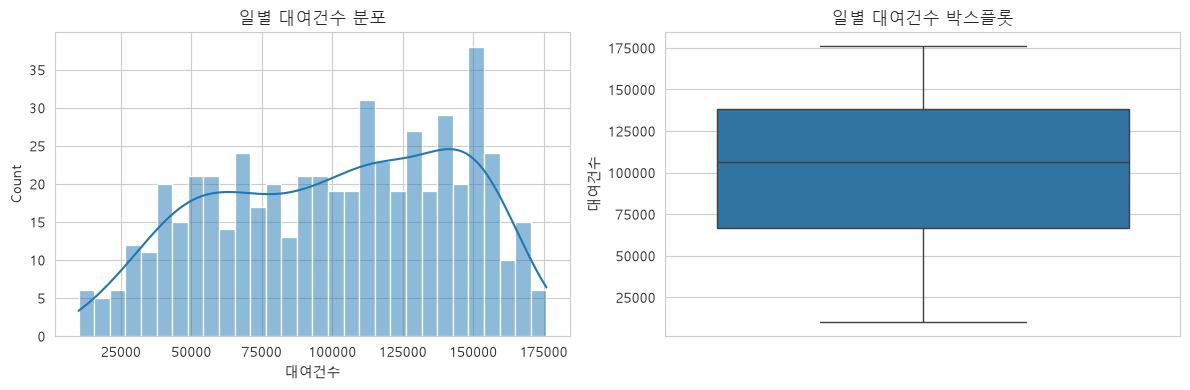

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["rentals"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("일별 대여건수 분포")
axes[0].set_xlabel("대여건수")

sns.boxplot(y=df["rentals"], ax=axes[1])
axes[1].set_title("일별 대여건수 박스플롯")
axes[1].set_ylabel("대여건수")

plt.tight_layout()
plt.show()


**해석**: 분포가 완만하게 넓게 퍼져 있고(약 1만~17.6만 건) 한쪽으로 심하게 치우치지는 않았다.
박스플롯 상으로 뚜렷한 극단 이상치는 보이지 않으며, 최솟값(약 1만 건) 근처는 한파·폭염 등
이용이 급감하는 날로 추정된다(관찰 — 원인은 아래 변수 간 관계에서 확인).


### 2) 집단 간 차이 — 강수 여부(`is_rain`)에 따른 대여건수

C:\Users\SSAFY\AppData\Local\Temp\ipykernel_4696\1272412197.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["비 안 옴", "비 옴"])


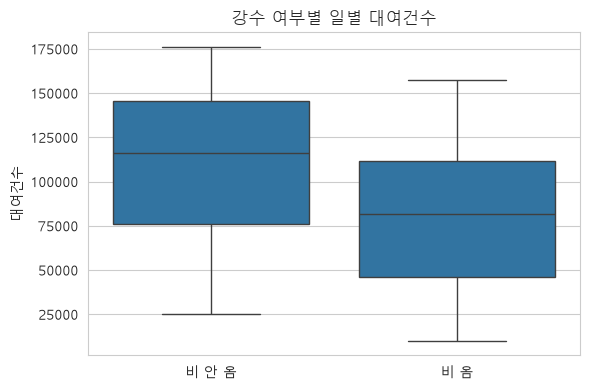

,mean,median,count
is_rain,,,
False,109968.191816,116047.0,391
True,79706.580645,81594.0,155


In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="is_rain", y="rentals", ax=ax)
ax.set_xticklabels(["비 안 옴", "비 옴"])
ax.set_xlabel("")
ax.set_ylabel("대여건수")
ax.set_title("강수 여부별 일별 대여건수")
plt.tight_layout()
plt.show()

df.groupby("is_rain")["rentals"].agg(["mean", "median", "count"])


**해석**: 비가 온 날은 비가 오지 않은 날보다 평균 대여건수가 뚜렷하게 낮다. 중앙값도 함께 낮아
일부 극단값 때문이 아니라 전반적인 이용량 자체가 줄어드는 경향으로 보인다(관찰). 다만 강수일이
비강수일보다 표본 수가 훨씬 적어(위 `count` 참고) 계절 편중 가능성은 추가 확인이 필요하다(한계는 F405에서 다룸).


### 3) 시간 변화 — 월별 추이 및 2025 vs 2026 비교

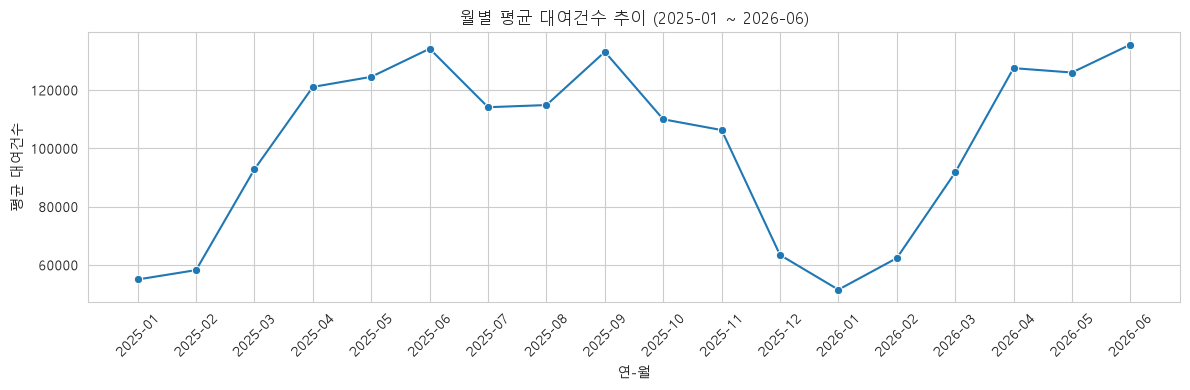

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
monthly = df.groupby("yearmonth")["rentals"].mean().reset_index()
sns.lineplot(data=monthly, x="yearmonth", y="rentals", marker="o", ax=ax)
ax.set_title("월별 평균 대여건수 추이 (2025-01 ~ 2026-06)")
ax.set_xlabel("연-월")
ax.set_ylabel("평균 대여건수")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


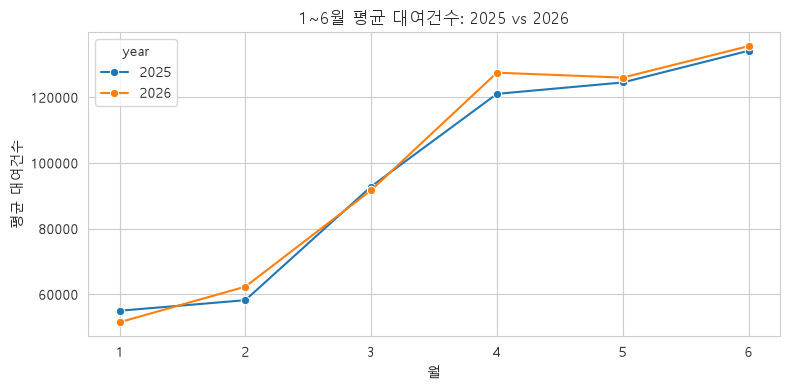

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
compare = df[df["month"] <= 6].groupby(["year", "month"])["rentals"].mean().reset_index()
sns.lineplot(data=compare, x="month", y="rentals", hue="year", marker="o", palette="tab10", ax=ax)
ax.set_title("1~6월 평균 대여건수: 2025 vs 2026")
ax.set_xlabel("월")
ax.set_ylabel("평균 대여건수")
ax.set_xticks(range(1, 7))
plt.tight_layout()
plt.show()


**해석**: 월별 추이는 겨울(12~2월)에 낮고 봄~초여름(5~6월)에 높아지는 뚜렷한 계절 패턴을 보인다
(관찰 — 기온 상승과 함께 증가하는 경향, 다음 절의 상관관계로 교차 확인). 2025년과 2026년의 같은
1~6월을 비교하면 전체적인 월별 패턴(겨울 낮음 → 초여름 높음)은 유사하게 반복되지만, 월별 평균 수준에는
연도 간 차이가 존재한다(관찰 — 구체적 증감 방향·폭의 해석과 원인 추정은 F405에서 다룬다).


### 4) 변수 간 관계 — 기상 변수와 대여건수

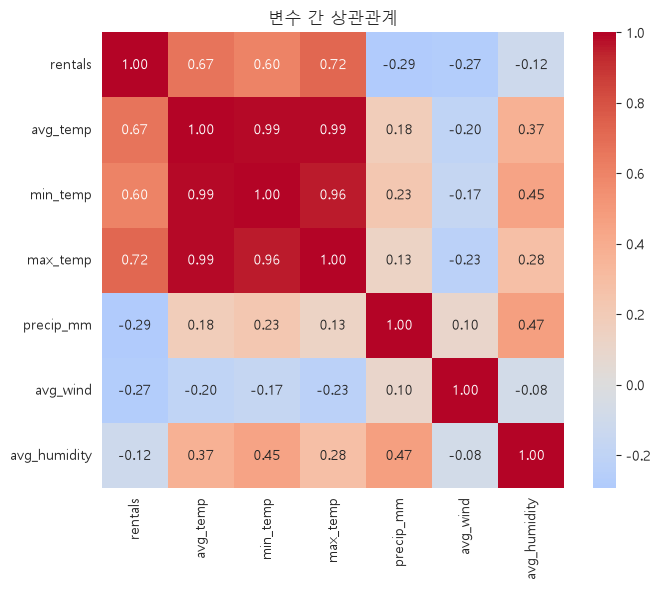

In [18]:
num_cols = ["rentals", "avg_temp", "min_temp", "max_temp", "precip_mm", "avg_wind", "avg_humidity"]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("변수 간 상관관계")
plt.tight_layout()
plt.show()


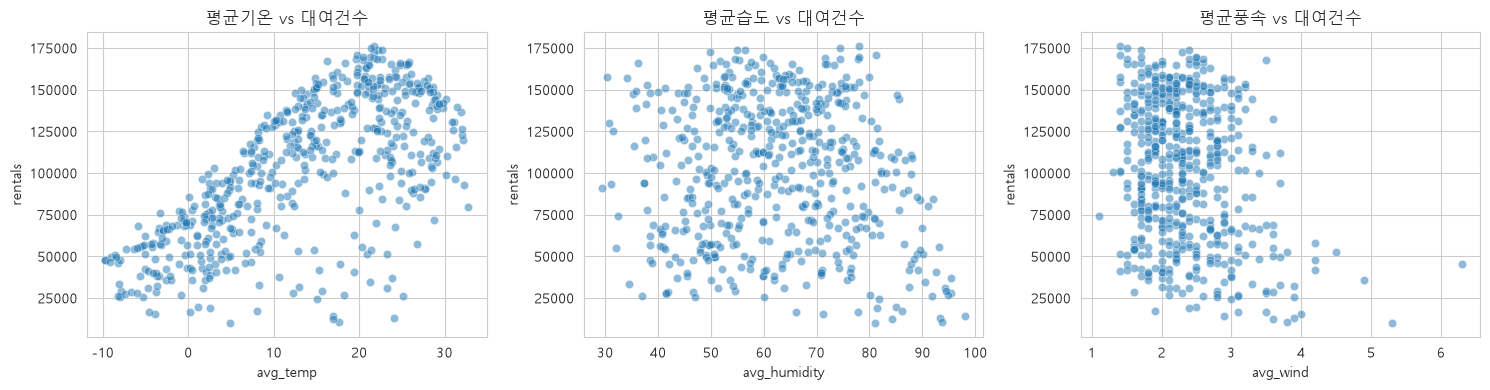

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(data=df, x="avg_temp", y="rentals", alpha=0.5, ax=axes[0])
axes[0].set_title("평균기온 vs 대여건수")

sns.scatterplot(data=df, x="avg_humidity", y="rentals", alpha=0.5, ax=axes[1])
axes[1].set_title("평균습도 vs 대여건수")

sns.scatterplot(data=df, x="avg_wind", y="rentals", alpha=0.5, ax=axes[2])
axes[2].set_title("평균풍속 vs 대여건수")

plt.tight_layout()
plt.show()


**해석**: 상관관계 히트맵에서 기온 계열 변수(특히 `max_temp`)가 `rentals`와 가장 강한 양의 상관(0.6~0.72)을
보인다. `precip_mm`(강수량, -0.29)과 `avg_wind`(평균풍속, -0.27)는 비슷한 수준의 약한 음의 상관을 보여 앞선
강수 여부 분석과 같은 방향이며, `avg_humidity`(평균습도, -0.12)는 그중 가장 약한 상관을 보인다. 산점도에서도
기온이 오를수록 대여건수가 증가하는 경향이 가장 뚜렷하다(관찰 — 상관관계이며 인과관계를 의미하지는 않음).


### F404 결과 요약

- **분포**: 일별 대여건수는 완만하게 넓은 분포(1만~17.6만 건)를 보이며 뚜렷한 극단 이상치는 없다.
- **집단 차이**: 비 온 날은 비 안 온 날보다 평균·중앙값 모두 낮아 강수가 이용량을 낮추는 방향으로 작용하는 것으로 관찰된다.
- **시간 변화**: 겨울에 낮고 초여름에 높은 계절 패턴이 뚜렷하며, 2025·2026년 1~6월 비교에서도 같은 패턴이 반복되나 연도별 수준 차이가 존재한다.
- **변수 관계**: 기온(특히 최고기온)이 대여건수와 가장 강하게 양의 상관(0.6~0.72)을 보이고, 강수량·풍속은 비슷한 수준(-0.27~-0.29)의 약한 음의 상관을, 습도(-0.12)는 가장 약한 상관을 보인다.

이 관찰들을 사실(fact)과 해석(interpretation)으로 구분해 인사이트로 정리하고 한계·후속 문제를 제안하는 것은
**F405**(2차 담당 신현준)에서 이어서 진행한다.


## F405. 인사이트·한계 및 후속 머신러닝 문제

담당: 신현준. F404의 관찰을 재계산한 수치로 뒷받침하고 사실과 해석을 구분한다. 검정 없이 통계적 유의성을 주장하지 않는다.


In [20]:
# F405: 원본/전처리 파일을 변경하지 않고 최종 분석 데이터를 독립적으로 로딩한다.
from pathlib import Path
import pandas as pd
f405 = pd.read_csv('../data/processed/merged_daily.csv', parse_dates=['date']).sort_values('date')
assert len(f405) == 546 and f405['date'].is_unique
assert not f405.isna().any().any()
rain_summary = f405.groupby('is_rain')['rentals'].agg(['count', 'mean', 'median'])
print('강수 여부별 요약 (건/일)')
print(rain_summary.round(2).to_string())
rain_gap = (rain_summary.loc[True, 'mean'] / rain_summary.loc[False, 'mean'] - 1) * 100
print(f'강수일 평균의 비강수일 대비 차이: {rain_gap:.2f}%')
print('대여량과 기상변수의 Pearson 상관계수')
print(f405.select_dtypes(include='number').corr()['rentals'].drop('rentals').round(4).to_string())
h1 = f405[f405['date'].dt.month <= 6].copy()
h1['year'] = h1['date'].dt.year
h1['month'] = h1['date'].dt.month
month_compare = h1.groupby(['month','year'])['rentals'].mean().unstack('year')
month_compare['change_pct'] = (month_compare[2026] / month_compare[2025] - 1) * 100
print('동일 월 일평균 대여량 비교: 2025 → 2026')
print(month_compare.round(2).to_string())
print('1~6월 전체 일평균:')
print(h1.groupby('year')['rentals'].agg(['count','mean']).round(2).to_string())


강수 여부별 요약 (건/일)
         count       mean    median
is_rain                            
False      391  109968.19  116047.0
True       155   79706.58   81594.0
강수일 평균의 비강수일 대비 차이: -27.52%
대여량과 기상변수의 Pearson 상관계수
avg_temp        0.6683
min_temp        0.6040
max_temp        0.7188
precip_mm      -0.2944
avg_wind       -0.2703
avg_humidity   -0.1167
동일 월 일평균 대여량 비교: 2025 → 2026
year        2025       2026  change_pct
month                                  
1       54978.58   51477.97       -6.37
2       58197.86   62310.46        7.07
3       92804.87   91686.58       -1.20
4      121026.67  127477.33        5.33
5      124496.39  125974.06        1.19
6      134143.83  135556.03        1.05
1~6월 전체 일평균:
      count      mean
year                 
2025    181  97930.00
2026    181  99331.44


### 관찰한 사실과 해석

위 표의 수치는 이 데이터의 기술통계이며 다른 기간이나 모집단의 효과 추정치가 아니다.

| 관찰한 사실 | 해석·활용 가설 | 검증에 필요한 정보 |
| --- | --- | --- |
| 기온 계열은 대여량과 양의 상관이며 최고기온의 상관이 약 0.72로 가장 크다. | 기온과 함께 수요가 달라져 기상 변수가 수요 예측에 유용할 가능성이 있다. 계절과 기온이 함께 변하므로 독립적인 온도 효과로 해석할 수 없다. | 계절·요일 통제, 비선형성 및 시점별 예측 검증 |
| 강수일 155일 평균은 약 79,707건, 비강수일 391일 평균은 약 109,968건이다. 강수일 평균이 약 27.52% 낮다. 중앙값도 각각 81,594건과 116,047건이다. | 강수일에 낮은 이용량이 관찰된다. 운영량 조정의 후보 근거이나, 강수 때문에 27.52% 감소했다고 단정할 수 없다. | 계절·요일·휴일을 고려한 비교, 강수 관측 품질 확인 |
| F404 월별 그래프는 겨울에 낮고 봄~초여름에 높아지는 패턴을 보인다. | 날씨뿐 아니라 계절에 따른 생활 패턴이 섞여 있을 수 있어 달력 변수를 추가할 가치가 있다. | 여러 해의 반복 관측, 휴일·방학·운영 변화 |
| 연도 비교는 위 표처럼 같은 1~6월끼리 수행한다. | 연도별 수준 차이는 날씨, 서비스 규모, 이용자 변화 등 여러 설명이 가능하다. 원인을 이 데이터만으로 식별할 수 없다. | 대여소·자전거 수, 정책·요금·운영 변화 기록 |

2025년과 2026년 1~6월 일평균은 각각 97,930건과 99,331건으로 약 1.43% 증가했다. 월별로는 1월 -6.37%, 2월 +7.07%, 3월 -1.20%, 4월 +5.33%, 5월 +1.19%, 6월 +1.05%로 증감 방향이 일정하지 않다. 따라서 전 기간의 일관된 증가로 일반화하지 않는다.

**활용 범위:** 서울시 전체 일별 수요 규모를 파악하는 기초 자료이다. 대여소별 재배치 위치나 특정 시간대 운영량을 직접 결정할 근거는 아니다.

### 데이터와 분석의 한계

1. 분석 기간은 2025-01-01~2026-06-30의 546일이다. 2026년 하반기가 없어 두 연도의 연간 총량을 직접 비교할 수 없으며, 여름·겨울의 반복 관측도 부족하다.
2. ASOS 전체 652일의 강수량 결측 386건을 0으로 대체했다. 이 수치는 분석용 546일의 결측 건수와 다르다. 무강수라는 가정이 틀리면 강수별 비교와 모델이 편향될 수 있다.
3. `is_rain`의 실제 생성식은 `sumRn.notna() & (sumRn > 0)`이다. 따라서 False에는 원래 결측과 실제 0mm가 함께 포함된다. 원래 결측 여부를 완전히 보존한 플래그가 아니며, 복원하려면 ASOS 원본을 날짜로 다시 결합해야 한다. HANDOFF의 플래그 설명보다 이 생성식을 우선한다.
4. 서울 전체 대여량과 서울 ASOS 한 지점의 날씨를 결합했다. 지역·시간대별 날씨와 수요 차이를 설명하지 못한다.
5. 상관계수와 집단별 평균은 계절·요일·휴일·추세를 통제하지 않았다. 일별 관측의 자기상관도 있어 단순 독립표본 가정의 유의성 주장은 부적절하다. F404 질문의 '유의미'는 기술적 차이 확인까지만 충족하며 통계적 유의성은 검증하지 않았다.
6. 온도 변수끼리 상관되어 단변량 상관 순위를 독립적인 중요도 순위로 해석할 수 없다. 폭염·한파의 원인도 최솟값만으로 확정할 수 없다.
7. 일별 관측 날씨는 당일 종료 후 확정된다. 이를 사용한 모델은 사후 조건부 예측 실험이며 실제 전일 수요 예측 성능과 다르다.

### 후속 머신러닝 문제 설계

- **문제:** 다음 날 서울시 전체 따릉이 대여건수 예측(회귀). 예측 시점은 전일 저녁으로 고정한다.
- **목표:** 운영 인력·자전거 공급량 계획에 참고할 전체 수요 예측. 대여소별 배치 문제는 별도 데이터가 필요하다.
- **입력:** 예측 시점에 발행된 다음 날 기상예보, 미리 알려진 요일·월·공휴일, 그 시점까지의 대여량 지연값. 당일 관측 날씨와 미래 대여량은 실제 서비스 입력에서 제외한다.
- **기준선:** 전주 동일 요일 대여량 및 과거 학습기간 평균. 확장 모델은 날씨와 달력을 결합한 회귀부터 비교한다.
- **분할:** 시간순 학습·검증·테스트. 학습 내부 확장창 검증으로 방법을 정하고 최종 테스트는 고정한다. 무작위 분할, 전체 기간으로 전처리 학습, 미래를 포함한 이동평균을 금지한다.
- **평가:** MAE(건/일), RMSE(큰 오차에 민감), WAPE(총 절대오차/총 실제량). 계절·강수별 오차도 확인한다. 점수는 인과 효과가 아니다.
- **추가 정보:** 발행 시각을 포함한 기상예보 이력, 공휴일·행사, 서비스 규모 변화, 더 긴 대여량 이력. 대여소별 예측으로 확장 시 대여소별 수요·재고·위치가 필요하다.

### F406 연결

달력 변수가 계절·생활 패턴을 보완할 수 있다는 가설을 검증한다. 외부 자료 없이 날짜에서 요일·연중 주기를 파생하고 **날씨만 사용한 모델 vs 날씨+달력 모델**을 같은 시간 분할에서 비교한다. 현재 확보한 관측 날씨를 사용하므로 실제 서비스 예측이 아닌 사후 예측 실험으로 한정한다.


## F406. 달력 변수 추가에 따른 예측 분석 확장

### 목적과 사전 고정한 비교 방법

F405에서 제기한 계절·생활 패턴의 누락을 보완하기 위해 날짜에서 달력 변수를 파생한다. **추가 외부 데이터 없이 분석 방법을 확장**하는 F406이다.

- 확장 전: 평균기온·기온 제곱·강수량·풍속·습도 기반 Ridge 회귀.
- 확장 후: 동일 기상 변수에 요일 원핫 인코딩과 연중 주기 sin/cos를 추가한 Ridge 회귀.
- 평균·최저·최고기온을 모두 넣는 대신 평균기온과 제곱항으로 단순한 비선형성을 표현한다. 두 모델 모두 같은 기상 입력을 사용한다.
- 두 모델의 alpha=10은 고정하고 테스트 결과로 튜닝하지 않는다. 표준화와 요일 인코딩은 각 학습 구간에서만 학습한다.
- 2025년 365일 학습, 2026-01-01~06-30의 181일 최종 평가. 학습기간 내부에서는 확장창 3분할(각 검증 60일)을 추가 보고한다.
- 학습 평균과 전주 동일 요일(7일 지연값) 기준선도 비교한다. 지연 기준선은 매일 과거 실제값이 갱신되는 1일 단위 평가이며 181일 일괄 예측이 아니다.
- 관측 날씨를 이용하는 **사후 조건부 예측 실험**이다. 실제 전일 운영 예측에는 당시 발행된 기상예보로 다시 검증해야 한다.


In [21]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

ext = f405.sort_values('date').reset_index(drop=True).copy()
assert ext['date'].diff().dropna().eq(pd.Timedelta(days=1)).all()
ext['temp_sq'] = ext['avg_temp'] ** 2
ext['weekday'] = ext['date'].dt.dayofweek
phase = 2 * np.pi * (ext['date'].dt.dayofyear - 1) / 365.25
ext['year_sin'], ext['year_cos'] = np.sin(phase), np.cos(phase)
ext['lag7'] = ext['rentals'].shift(7)  # 과거 값만 사용: 당일 목표값은 포함하지 않는다
weather_features = ['avg_temp', 'temp_sq', 'precip_mm', 'avg_wind', 'avg_humidity']

def make_model(calendar=False):
    numeric = weather_features + (['year_sin', 'year_cos'] if calendar else [])
    transforms = [('numeric', StandardScaler(), numeric)]
    if calendar:
        transforms.append(('weekday', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['weekday']))
    return Pipeline([('features', ColumnTransformer(transforms)), ('ridge', Ridge(alpha=10.0))])

def scores(y, prediction):
    return {'MAE': mean_absolute_error(y, prediction),
            'RMSE': np.sqrt(mean_squared_error(y, prediction)),
            'WAPE_pct': 100 * np.abs(np.asarray(y)-prediction).sum() / np.asarray(y).sum()}

train = ext[ext['date'] < '2026-01-01'].copy()
test = ext[ext['date'] >= '2026-01-01'].copy()
assert len(train) == 365 and len(test) == 181
assert train['date'].max() < test['date'].min()
print('학습 / 최종 평가 기간')
print(train['date'].min().date(), train['date'].max().date(), len(train))
print(test['date'].min().date(), test['date'].max().date(), len(test))
cv_records = []
for fold, (tr_idx, va_idx) in enumerate(TimeSeriesSplit(n_splits=3, test_size=60).split(train), 1):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]
    assert tr['date'].max() < va['date'].min()
    for name, calendar in [('weather', False), ('weather_calendar', True)]:
        model = make_model(calendar)
        model.fit(tr, tr['rentals'])
        prediction = np.maximum(model.predict(va), 0)
        cv_records.append({'fold': fold, 'model': name, 'train_end': str(tr['date'].max().date()),
                           'valid_start': str(va['date'].min().date()), 'valid_end': str(va['date'].max().date()),
                           **scores(va['rentals'], prediction)})
cv_results = pd.DataFrame(cv_records)
print('2025년 내부 시간순 검증 (건/일, WAPE는 %)')
print(cv_results.round(2).to_string(index=False))

predictions = pd.DataFrame({'date': test['date'], 'actual': test['rentals'], 'is_rain': test['is_rain']})
predictions['train_mean'] = train['rentals'].mean()
predictions['lag7'] = test['lag7']
for name, calendar in [('weather', False), ('weather_calendar', True)]:
    model = make_model(calendar)
    model.fit(train, train['rentals'])
    predictions[name] = np.maximum(model.predict(test), 0)  # 대여량의 비음수 범위로 제한
model_names = ['train_mean', 'lag7', 'weather', 'weather_calendar']
metrics = pd.DataFrame([{'model': name, **scores(predictions['actual'], predictions[name])} for name in model_names])
print('2026년 상반기 고정 최종 평가')
print(metrics.round(2).to_string(index=False))
before = metrics.set_index('model').loc['weather', 'MAE']
after = metrics.set_index('model').loc['weather_calendar', 'MAE']
print(f'달력 변수 추가의 MAE 개선율: {(before-after)/before*100:.2f}% (음수면 악화)')

out_dir = Path('../outputs/f406')
out_dir.mkdir(parents=True, exist_ok=True)
cv_results.to_csv(out_dir / 'time_cv_metrics.csv', index=False)
metrics.to_csv(out_dir / 'holdout_metrics.csv', index=False)
predictions.to_csv(out_dir / 'holdout_predictions.csv', index=False)


학습 / 최종 평가 기간
2025-01-01 2025-12-31 365
2026-01-01 2026-06-30 181
2025년 내부 시간순 검증 (건/일, WAPE는 %)
 fold            model  train_end valid_start  valid_end      MAE     RMSE  WAPE_pct
    1          weather 2025-07-04  2025-07-05 2025-09-02 38730.99 46229.14     34.42
    1 weather_calendar 2025-07-04  2025-07-05 2025-09-02 26294.49 32559.10     23.37
    2          weather 2025-09-02  2025-09-03 2025-11-01 28227.21 32475.17     23.36
    2 weather_calendar 2025-09-02  2025-09-03 2025-11-01 40643.33 45964.89     33.63
    3          weather 2025-11-01  2025-11-02 2025-12-31 14814.09 17536.48     17.57
    3 weather_calendar 2025-11-01  2025-11-02 2025-12-31 11139.72 13608.12     13.21
2026년 상반기 고정 최종 평가
           model      MAE     RMSE  WAPE_pct
      train_mean 36170.26 41515.88     36.41
            lag7 21046.76 32580.63     21.19
         weather 16212.48 20634.83     16.32
weather_calendar 12382.94 16629.42     12.47
달력 변수 추가의 MAE 개선율: 23.62% (음수면 악화)


  group value   n            model      MAE     RMSE  WAPE_pct
  month     1  31          weather 11473.89 15113.05     22.29
  month     1  31 weather_calendar  7795.77  9755.72     15.14
  month     2  28          weather 22920.45 28031.08     36.78
  month     2  28 weather_calendar 16488.52 22560.77     26.46
  month     3  31          weather 16754.42 21380.71     18.27
  month     3  31 weather_calendar 12041.81 14896.10     13.13
  month     4  30          weather 13418.67 16699.92     10.53
  month     4  30 weather_calendar 11739.92 16674.09      9.21
  month     5  31          weather 17362.11 21239.44     13.78
  month     5  31 weather_calendar 13552.21 17893.76     10.76
  month     6  30          weather 15894.12 19549.52     11.73
  month     6  30 weather_calendar 13078.42 16027.07      9.65
is_rain False 143          weather 15485.87 19887.00     15.02
is_rain False 143 weather_calendar 10769.31 14587.09     10.45
is_rain  True  38          weather 18946.83 23234.32   

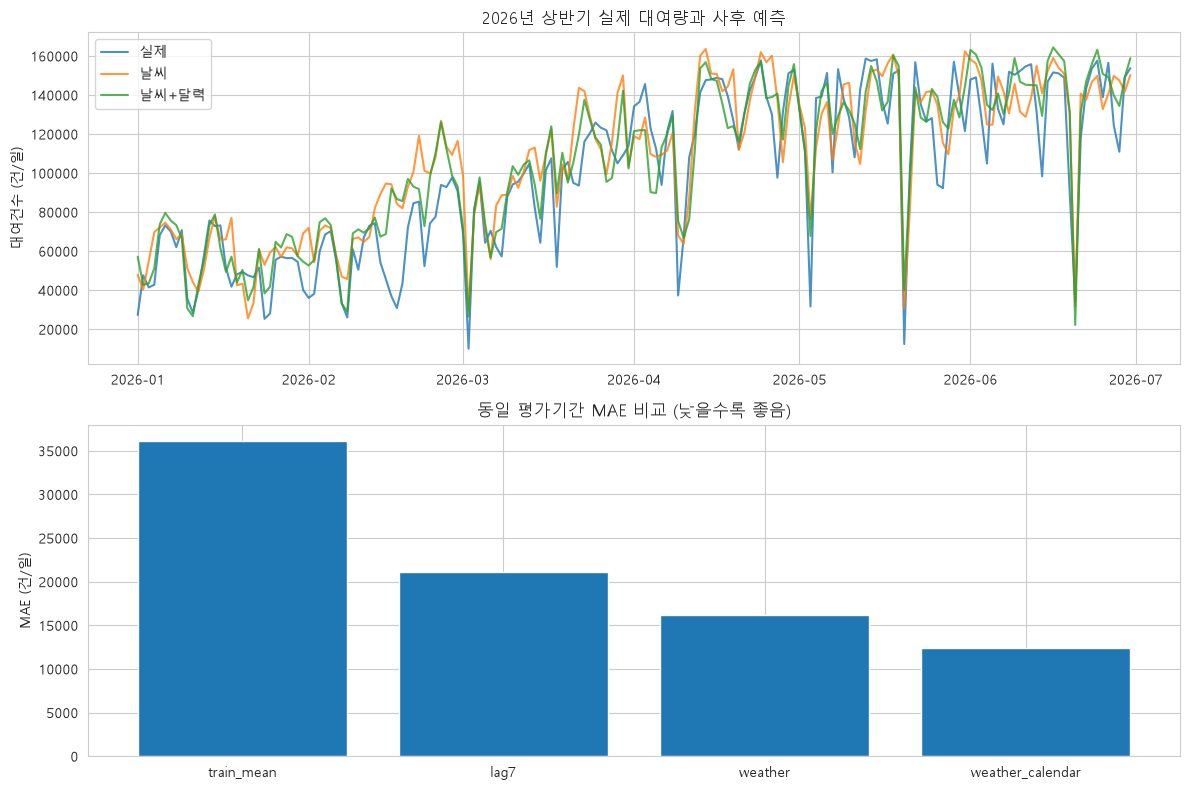

In [22]:
# 월·강수별 오차를 확인해 전체 평균이 숨기는 실패 구간을 점검한다.
subgroup_records = []
for group_name, group_values in [('month', predictions['date'].dt.month), ('is_rain', predictions['is_rain'])]:
    for value in sorted(group_values.unique()):
        part = predictions.loc[group_values == value]
        for name in ['weather', 'weather_calendar']:
            subgroup_records.append({'group': group_name, 'value': str(value), 'n': len(part),
                                     'model': name, **scores(part['actual'], part[name])})
subgroup_metrics = pd.DataFrame(subgroup_records)
print(subgroup_metrics.round(2).to_string(index=False))
subgroup_metrics.to_csv(out_dir / 'subgroup_metrics.csv', index=False)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for column, label in [('actual', '실제'), ('weather', '날씨'), ('weather_calendar', '날씨+달력')]:
    axes[0].plot(predictions['date'], predictions[column], label=label, alpha=0.8)
axes[0].set_title('2026년 상반기 실제 대여량과 사후 예측')
axes[0].set_ylabel('대여건수 (건/일)')
axes[0].legend()
axes[1].bar(metrics['model'], metrics['MAE'])
axes[1].set_title('동일 평가기간 MAE 비교 (낮을수록 좋음)')
axes[1].set_ylabel('MAE (건/일)')
fig.tight_layout()
fig.savefig(out_dir / 'comparison.png', dpi=150)
plt.show()


### 확장 전후 결과와 해석

2026년 상반기 181일의 고정 평가 결과:

| 방법 | MAE (건/일) | RMSE (건/일) | WAPE |
| --- | ---: | ---: | ---: |
| 학습기간 평균 | 36,170 | 41,516 | 36.41% |
| 전주 동일 요일 | 21,047 | 32,581 | 21.19% |
| 날씨 회귀 (확장 전) | 16,212 | 20,635 | 16.32% |
| 날씨+달력 회귀 (확장 후) | 12,383 | 16,629 | 12.47% |

**관찰:** 달력 변수 추가로 MAE가 약 23.62% 감소했다. 같은 평가기간의 1~6월 모두 MAE가 낮아졌다. 다만 강수일 38일의 MAE는 18,947 → 18,455건으로 개선이 작고, 비강수일 143일의 15,486 → 10,769건보다 오차가 크다.

**해석:** 이 기간에는 달력 정보가 날씨만으로 포착하지 못한 변동을 보완했다. 요일과 연중 주기를 함께 추가했으므로 어느 변수가 개선을 주도했는지는 이 비교로 분리할 수 없고, 달력이 수요를 변화시킨 인과 효과도 아니다.

**새롭게 확인한 한계:** 2025년 내부 시간순 검증의 두 번째 구간(9~11월)에서는 확장 후 MAE가 28,227 → 40,643건으로 악화했다. 나머지 구간과 최종 평가에서는 개선했지만, 시점에 따라 효과가 달라 일관된 우월성을 주장할 수 없다. 학습 초기의 계절 관측 부족과 연중 주기의 외삽이 가능한 설명이며 원인은 확정하지 않는다.

**남은 한계와 다음 단계:** 학습은 1년, 최종 평가는 상반기뿐이다. 신뢰구간과 통계적 유의성은 산출하지 않았으며 테스트 결과를 보고 모델을 다시 선택·튜닝하지 않았다. 실제 운영 검증에는 더 긴 기간, 시점별 기상예보, 공휴일·운영 규모가 필요하다. 강수일 오차를 줄이는 방법도 별도 검증해야 한다. 본 실험은 관측 날씨 기반 사후 비교이므로 실제 전일 예보 성능으로 보고하지 않는다.

### F405·F406 검토 상태

두 요구사항의 코드·실행 결과·해석 작성 및 전체 재실행 완료. 검토 대기 상태이며 master 병합과 최종 제출은 아직 하지 않았다. F405와 F406은 각각 별도 기능 브랜치·커밋으로 관리한다.
